# 18 - Citi Bike final test

**Question:** how well does the frozen next-day forecast work on later dates?

Final evaluation: Tomislav Novosel, with Codex assistance. Reviewed by the team on 22 October 2026.

We chose the 75% GRU / 25% CatBoost blend because it had the lowest recorded development MAE. We kept the original fit trained through June. Existing uncertainty checks did not prove a dependable advantage over XGBoost.

Before opening test targets, weather preflight found incomplete GFS temperature hours on 29-31 December. We preserved the first freeze and recorded a counts-only XGBoost fallback before scoring. We did not invent weather or use observations.

The once-only test covered 1 October-31 December 2023. This notebook reads its saved predictions; it does not refit or rerun the test.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import sys
ROOT = Path.cwd() if (Path.cwd() / "release_decision.json").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.release_integrity import verify_release, digest
release = verify_release(required=True)
results = json.loads((ROOT / "reports/final_test_results.json").read_text())
assert results["status"] == "complete"
assert results["decision_sha256"] == digest(ROOT / "release_decision.json", text=True)
print("Frozen before testing:", release["utc"])
print("Final evaluation completed:", results["utc"])
print("Operator:", results["operator"], "- Codex assistance")


Frozen before testing: 2026-10-13T19:05:46.188770+00:00
Final evaluation completed: 2026-10-13T19:06:07.975394+00:00
Operator: Tomislav Novosel - Codex assistance


In [2]:
predictions=pd.read_csv(ROOT / "reports/final_bike_predictions.csv",parse_dates=["date"])
assert digest(ROOT / "reports/final_bike_predictions.csv",text=True)==results["prediction_hashes"]["final_bike_predictions.csv"]
assert len(predictions)==92
print("Final dates:",predictions.date.min().date(),"to",predictions.date.max().date())
print("Fallback dates:",results["bike_fallback_dates"])
display(predictions.groupby("used_model").size().rename("days").to_frame())


Final dates: 2023-10-01 to 2023-12-31
Fallback dates: ['2023-12-29', '2023-12-30', '2023-12-31']


,days
used_model,
counts,3
weather_gru,89


## Make a fair comparison

Each forecast is one day ahead. It uses the previous 28 completed daily totals and archived forecast inputs. After a test day finishes, that count can become history for a later forecast. No target day's count enters its own inputs.

The last-week baseline uses the count seven days earlier. Both release and baseline cover the same 92 dates. The separate 89-day comparison below uses only complete-weather dates. MAE is average error size. RMSE gives more weight to large errors. Lower is better.

In [3]:
rows=[]
for name,key in [("Release + fallback, all days","citibike"),("Last week, all days","citibike_lag_7"),
                 ("GRU blend, weather complete","citibike_weather_complete"),
                 ("Last week, same weather-complete days","citibike_lag_7_weather_complete")]:
    m=results[key]
    rows.append({"forecast":name,"days":m["days"],"MAE":m["mae"],"RMSE":m["rmse"],
                 "WAPE":m["wape"],"mean overprediction":m["bias"]})
display(pd.DataFrame(rows).set_index("forecast").round(2))
improvement=1-results["citibike"]["mae"]/results["citibike_lag_7"]["mae"]
print(f"MAE reduction against last week's count: {improvement:.1%}")


,days,MAE,RMSE,WAPE,mean overprediction
forecast,,,,,
"Release + fallback, all days",92,15005.05,21142.90,0.16,5828.77
"Last week, all days",92,24254.79,33689.25,0.26,2296.38
"GRU blend, weather complete",89,15366.60,21474.78,0.16,5937.96
"Last week, same weather-complete days",89,24774.03,34205.90,0.26,2672.12


MAE reduction against last week's count: 38.1%


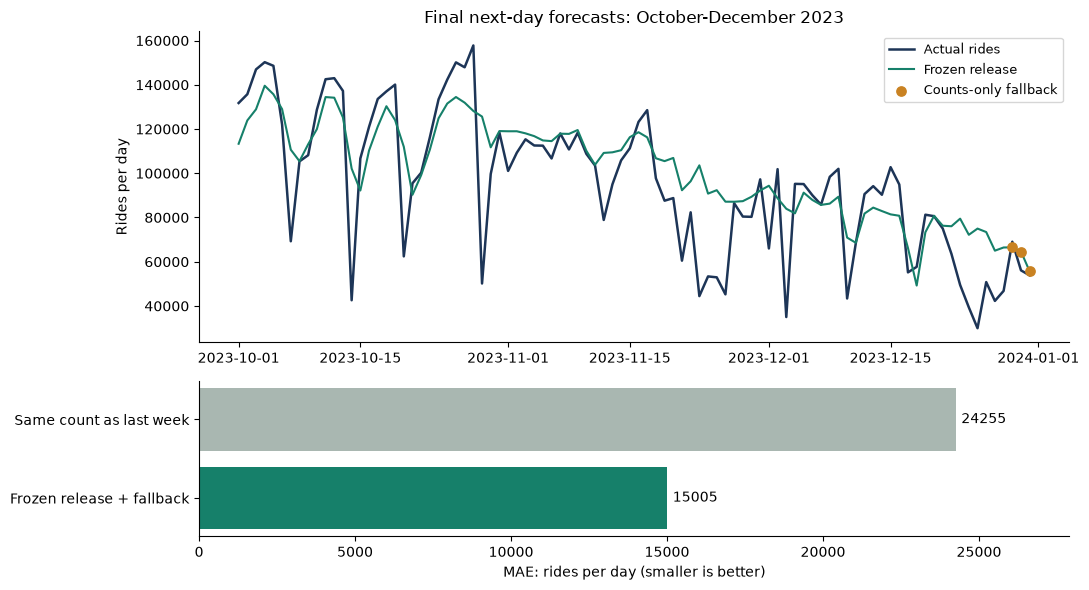

In [4]:
fig,(ax,bar)=plt.subplots(2,1,figsize=(11,6),gridspec_kw={"height_ratios":[2,1]})
ax.plot(predictions.date,predictions.actual,label="Actual rides",color="#1d3557",linewidth=1.8)
ax.plot(predictions.date,predictions.prediction,label="Frozen release",color="#16806a",linewidth=1.5)
fallback=predictions[predictions.used_model=="counts"]
ax.scatter(fallback.date,fallback.prediction,label="Counts-only fallback",color="#c98222",s=45,zorder=3)
ax.set_title("Final next-day forecasts: October-December 2023")
ax.set_ylabel("Rides per day")
ax.legend(loc="upper right",fontsize=9)
values=[results["citibike"]["mae"],results["citibike_lag_7"]["mae"]]
bars=bar.barh(["Frozen release + fallback","Same count as last week"],values,color=["#16806a","#a9b7b1"])
bar.bar_label(bars,fmt="%.0f",padding=4)
bar.set_xlim(0,max(values)*1.15)
bar.set_xlabel("MAE: rides per day (smaller is better)")
for a in [ax,bar]:a.spines[["top","right"]].set_visible(False)
fig.tight_layout()
fig.savefig(ROOT / "reports/final_bike_results.png",dpi=160,bbox_inches="tight")
plt.show()


## What this tells us

- Across 92 days, release MAE was 15,005 rides/day. Last week's count had MAE 24,255. The release reduced average error by 38.1% on this period.
- It overpredicted by 5,829 rides/day on average. Some quiet days still produced large errors.
- The GRU blend handled 89 dates (MAE 15,367). XGBoost handled the three dates with unavailable weather. The full-period score describes this combined release rule, not GRU alone.
- The archived forecasts use a 48-hour lead. Exact historical publication times remain unverified.

We reported these results without changing model settings. This is evidence for this held-out quarter, not a guarantee for future years. The demo has no live trip or weather feed.